In [3]:
# IMPORTING LIBRARIES

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sqlalchemy

print("All libraries are ready!")

All libraries are ready!


In [6]:
import sqlalchemy

print("SQLAlchemy version:", sqlalchemy.__version__)
print("SQLAlchemy location:", sqlalchemy.__file__)
print("Has dialects:", hasattr(sqlalchemy, "dialects"))

SQLAlchemy version: 2.1.4
SQLAlchemy location: C:\Users\harin\AppData\Local\Programs\Python\Python313\Lib\site-packages\sqlalchemy\__init__.py
Has dialects: False


In [10]:
# SQL CONNECTION

import mysql.connector

conn = mysql.connector.connect(
    host="localhost",
    user="root",
    password="System",
    database="job",
    port=3306
)

if conn.is_connected():
    print("Successfully connected to MySQL!")

Successfully connected to MySQL!


1. READ DATASET

In [11]:
companies = pd.read_sql("SELECT * FROM job_companies", conn)
countries = pd.read_sql("SELECT * FROM job_countries", conn)
platforms = pd.read_sql("SELECT * FROM job_platforms", conn)
postings = pd.read_sql("SELECT * FROM job_postings", conn)
skills = pd.read_sql("SELECT * FROM job_skills", conn)
skill_types = pd.read_sql("SELECT * FROM job_skill_types", conn)

C:\Users\harin\AppData\Local\Temp\ipykernel_26908\3521574783.py:1: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  companies = pd.read_sql("SELECT * FROM job_companies", conn)
C:\Users\harin\AppData\Local\Temp\ipykernel_26908\3521574783.py:2: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  countries = pd.read_sql("SELECT * FROM job_countries", conn)
C:\Users\harin\AppData\Local\Temp\ipykernel_26908\3521574783.py:3: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  platforms = pd.read_sql("SELECT * FROM job_platforms", conn)
C:\User

In [12]:
print("Companies:", companies.shape)
print("Countries:", countries.shape)
print("Platforms:", platforms.shape)
print("Job Postings:", postings.shape)
print("Skills:", skills.shape)
print("Job Skill Types:", skill_types.shape)

Companies: (20, 2)
Countries: (13, 3)
Platforms: (6, 2)
Job Postings: (3000, 12)
Skills: (26, 2)
Job Skill Types: (13477, 3)


In [13]:
dataframes = {
    "Companies": companies,
    "Countries": countries,
    "Platforms": platforms,
    "Job Postings": postings,
    "Skills": skills,
    "Job Skill Types": skill_types
}

for name, df in dataframes.items():
    print("\n" + "=" * 50)
    print(name)
    print("=" * 50)
    df.info()


Companies
<class 'pandas.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   company_id  20 non-null     int64
 1   company     20 non-null     str  
dtypes: int64(1), str(1)
memory usage: 452.0 bytes

Countries
<class 'pandas.DataFrame'>
RangeIndex: 13 entries, 0 to 12
Data columns (total 3 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   country_id  13 non-null     int64
 1   country     13 non-null     str  
 2   region      13 non-null     str  
dtypes: int64(1), str(2)
memory usage: 444.0 bytes

Platforms
<class 'pandas.DataFrame'>
RangeIndex: 6 entries, 0 to 5
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   platform_id  6 non-null      int64
 1   platform     6 non-null      str  
dtypes: int64(1), str(1)
memory usage: 228.0 bytes

Job Postings
<class 'pandas.Dat

2. EDA and Statistical Analysis

In [15]:
# 1. Overall statistical summary
print("=" * 60)
print("OVERALL JOB POSTINGS STATISTICS")
print("=" * 60)
display(postings.describe().round(2))


# 2. Salary statistical summary
print("\n" + "=" * 60)
print("SALARY STATISTICAL SUMMARY (USD)")
print("=" * 60)
salary_summary = postings[
    ['salary_min_usd', 'salary_max_usd', 'salary_mid_usd']
].describe().round(2)
display(salary_summary)


# 3. Applicants statistical summary
print("\n" + "=" * 60)
print("APPLICANTS ESTIMATE SUMMARY")
print("=" * 60)
applicants_summary = postings[
    ['applicants_estimate']
].describe().round(2)

display(applicants_summary)

OVERALL JOB POSTINGS STATISTICS


,company_id,country_id,platform_id,salary_min_usd,salary_max_usd,salary_mid_usd,applicants_estimate
count,3000.00,3000.00,3000.00,3000.00,3000.00,3000.00,3000.00
mean,10.56,7.00,3.47,112733.91,132720.35,122727.12,307.11
std,5.80,3.71,1.70,36773.37,37599.28,36936.31,171.23
min,1.00,1.00,1.00,45377.00,51408.00,48512.00,5.00
25%,6.00,4.00,2.00,82926.00,102823.25,92893.00,161.75
50%,11.00,7.00,3.00,114355.50,134008.00,124082.00,304.00
75%,16.00,10.00,5.00,141936.50,163003.00,152133.75,457.00
max,20.00,13.00,6.00,179895.00,212827.00,196048.00,600.00



SALARY STATISTICAL SUMMARY (USD)


,salary_min_usd,salary_max_usd,salary_mid_usd
count,3000.00,3000.00,3000.00
mean,112733.91,132720.35,122727.12
std,36773.37,37599.28,36936.31
min,45377.00,51408.00,48512.00
25%,82926.00,102823.25,92893.00
50%,114355.50,134008.00,124082.00
75%,141936.50,163003.00,152133.75
max,179895.00,212827.00,196048.00



APPLICANTS ESTIMATE SUMMARY


,applicants_estimate
count,3000.00
mean,307.11
std,171.23
min,5.00
25%,161.75
50%,304.00
75%,457.00
max,600.00


Skill Demand

In [21]:
# Skill Co-occurrence Analysis

# 1. Create job-skill matrix
job_skill_matrix = pd.crosstab(
    skill_types['job_id'],
    skill_types['skill_name']
)

# 2. Calculate skill combinations
skill_cooccurrence = job_skill_matrix.T.dot(job_skill_matrix)

# 3. Convert matrix into a readable DataFrame
skill_pairs = (
    skill_cooccurrence
    .rename_axis(index='Skill_1', columns='Skill_2')
    .reset_index()
    .melt(
        id_vars='Skill_1',
        var_name='Skill_2',
        value_name='Job_Count'
    )
)

# 4. Remove same-skill combinations
skill_pairs = skill_pairs[
    skill_pairs['Skill_1'] < skill_pairs['Skill_2']
]

# 5. Sort by number of postings
skill_pairs = skill_pairs.sort_values(
    'Job_Count',
    ascending=False
).reset_index(drop=True)

# 6. Display top 20 combinations
print("=" * 70)
print("TOP 20 SKILL COMBINATIONS")
print("=" * 70)

display(skill_pairs.head(20))

TOP 20 SKILL COMBINATIONS


,Skill_1,Skill_2,Job_Count
0,SQL,Tableau,101
1,ETL,TensorFlow,100
2,Airflow,ETL,100
3,Machine Learning,Spark,99
4,Azure,Tableau,99
5,Airflow,Python,99
6,BigQuery,Data Visualization,98
7,NumPy,TensorFlow,97
8,Excel,TensorFlow,97
9,NumPy,Pandas,97


Salary Outlier Detection

In [23]:
# Step 12: Salary Outlier Detection using IQR

# Calculate Q1 and Q3 separately for each job title
postings['Q1'] = postings.groupby('job_title')['salary_mid_usd'].transform(
    lambda x: x.quantile(0.25)
)

postings['Q3'] = postings.groupby('job_title')['salary_mid_usd'].transform(
    lambda x: x.quantile(0.75)
)

# Calculate Interquartile Range
postings['IQR'] = postings['Q3'] - postings['Q1']

# Calculate outlier boundaries
postings['Lower_Bound'] = postings['Q1'] - (1.5 * postings['IQR'])
postings['Upper_Bound'] = postings['Q3'] + (1.5 * postings['IQR'])

# Identify outliers
postings['Salary_Outlier'] = np.where(
    (postings['salary_mid_usd'] < postings['Lower_Bound']) |
    (postings['salary_mid_usd'] > postings['Upper_Bound']),
    'Outlier',
    'Normal'
)

# Summarise outliers by job title
outlier_summary = (
    postings.groupby('job_title')
    .agg(
        Total_Postings=('job_id', 'count'),
        Outlier_Count=('Salary_Outlier', lambda x: (x == 'Outlier').sum())
    )
    .reset_index()
)

outlier_summary['Outlier_Percentage'] = (
    outlier_summary['Outlier_Count'] /
    outlier_summary['Total_Postings'] * 100
)

outlier_summary = outlier_summary.sort_values(
    'Outlier_Count',
    ascending=False
).reset_index(drop=True)

print("=" * 70)
print("SALARY OUTLIER ANALYSIS BY JOB ROLE")
print("=" * 70)

display(outlier_summary.round(2))

# Display the actual unusual salary postings
salary_outliers = postings[
    postings['Salary_Outlier'] == 'Outlier'
][[
    'job_title',
    'experience_level',
    'country_id',
    'salary_mid_usd',
    'Lower_Bound',
    'Upper_Bound'
]].sort_values('salary_mid_usd', ascending=False)

print("\nUNUSUAL SALARY POSTINGS")
display(salary_outliers.head(20).round(2))

SALARY OUTLIER ANALYSIS BY JOB ROLE


,job_title,Total_Postings,Outlier_Count,Outlier_Percentage
0,AI Engineer,329,0,0.0
1,Analytics Engineer,313,0,0.0
2,Business Intelligence Analyst,321,0,0.0
3,Data Analyst,319,0,0.0
4,Data Engineer,324,0,0.0
5,Data Scientist,338,0,0.0
6,Machine Learning Engineer,340,0,0.0
7,Senior Data Analyst,219,0,0.0
8,Senior Data Engineer,256,0,0.0
9,Senior Data Scientist,241,0,0.0



UNUSUAL SALARY POSTINGS


,job_title,experience_level,country_id,salary_mid_usd,Lower_Bound,Upper_Bound


In [ ]:
Salary Prediction

SALARY PREDICTION MODEL PERFORMANCE

BASELINE MODEL
MAE:  $29,906.05
RMSE: $35,497.66
R2 Score: -0.0025

RANDOM FOREST MODEL
MAE:  $17,759.41
RMSE: $21,427.79
R2 Score: 0.6347

TOP FEATURE GROUPS INFLUENCING SALARY PREDICTION


,Feature_Group,Importance
0,job,0.8802
1,company,0.0386
2,country,0.0267
3,platform,0.0181
4,experience,0.0131
5,employment,0.0119
6,remote,0.0114


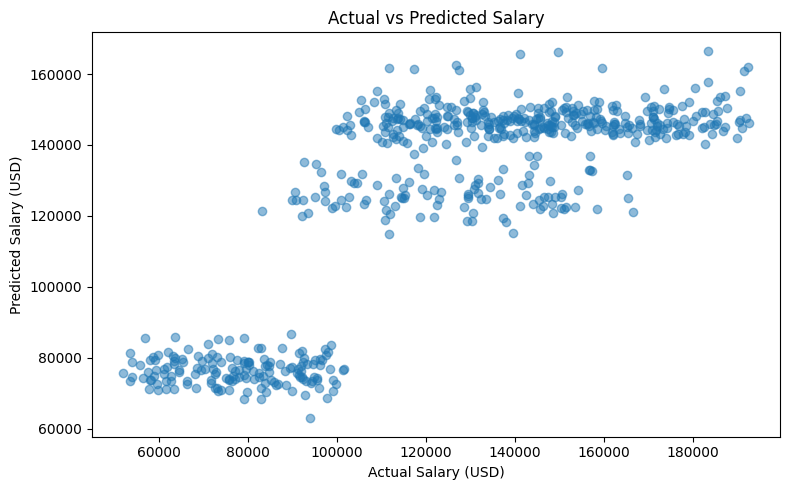

In [25]:
# Step 14: Salary Prediction using Random Forest

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Select input features
features = [
    'job_title',
    'company_id',
    'country_id',
    'platform_id',
    'experience_level',
    'employment_type',
    'remote_option'
]

X = postings[features]
y = postings['salary_mid_usd']

# 2. Identify categorical columns
categorical_features = features

# 3. Convert categorical values into numerical representation
preprocessor = ColumnTransformer(
    transformers=[
        ('categorical',
         OneHotEncoder(handle_unknown='ignore'),
         categorical_features)
    ]
)

# 4. Split dataset into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

# 5. Create a baseline model
baseline_model = DummyRegressor(strategy='mean')
baseline_model.fit(X_train, y_train)

baseline_predictions = baseline_model.predict(X_test)

# 6. Build Random Forest model
rf_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        max_depth=12,
        min_samples_split=5,
        min_samples_leaf=2,
        n_jobs=-1
    ))
])

# 7. Train the model
rf_model.fit(X_train, y_train)

# 8. Make predictions
predictions = rf_model.predict(X_test)

# 9. Evaluate both models
baseline_mae = mean_absolute_error(y_test, baseline_predictions)
baseline_rmse = np.sqrt(mean_squared_error(y_test, baseline_predictions))
baseline_r2 = r2_score(y_test, baseline_predictions)

model_mae = mean_absolute_error(y_test, predictions)
model_rmse = np.sqrt(mean_squared_error(y_test, predictions))
model_r2 = r2_score(y_test, predictions)

print("=" * 65)
print("SALARY PREDICTION MODEL PERFORMANCE")
print("=" * 65)

print("\nBASELINE MODEL")
print(f"MAE:  ${baseline_mae:,.2f}")
print(f"RMSE: ${baseline_rmse:,.2f}")
print(f"R2 Score: {baseline_r2:.4f}")

print("\nRANDOM FOREST MODEL")
print(f"MAE:  ${model_mae:,.2f}")
print(f"RMSE: ${model_rmse:,.2f}")
print(f"R2 Score: {model_r2:.4f}")

# 10. Extract feature importance
feature_names = (
    rf_model.named_steps['preprocessor']
    .get_feature_names_out()
)

importance = rf_model.named_steps['model'].feature_importances_

feature_importance = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importance
})

# Combine importance of categories belonging to the same original column
feature_importance['Feature_Group'] = (
    feature_importance['Feature']
    .str.replace('categorical__', '', regex=False)
    .str.split('_')
    .str[0]
)

group_importance = (
    feature_importance.groupby('Feature_Group')['Importance']
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

print("\nTOP FEATURE GROUPS INFLUENCING SALARY PREDICTION")
display(group_importance.round(4))

# 11. Visualise actual vs predicted salaries
plt.figure(figsize=(8, 5))

plt.scatter(
    y_test,
    predictions,
    alpha=0.5
)

plt.xlabel('Actual Salary (USD)')
plt.ylabel('Predicted Salary (USD)')
plt.title('Actual vs Predicted Salary')

plt.tight_layout()
plt.show()

TABLE 1. Skill combination for Job

In [26]:
# 1. Merge job postings with their associated skills
role_skill_data = skill_types.merge(
    postings[['job_id', 'job_title']],
    on='job_id',
    how='inner'
)

# 2. Create an empty list to store the results
skill_pair_results = []

# 3. Analyse each job role separately
for role, group in role_skill_data.groupby('job_title'):
    # Create a binary job-skill matrix for this role
    skill_matrix = pd.crosstab(
        group['job_id'],
        group['skill_name'])

    # Calculate skill co-occurrence
    cooccurrence = skill_matrix.T.dot(skill_matrix)

    # Calculate individual skill frequencies
    frequencies = skill_matrix.sum(axis=0)

    # Generate unique skill pairs
    for i in range(len(cooccurrence.columns)):
        for j in range(i + 1, len(cooccurrence.columns)):

            skill_1 = cooccurrence.columns[i]
            skill_2 = cooccurrence.columns[j]

            job_count = cooccurrence.iloc[i, j]

            # Calculate Jaccard similarity
            union_count = (
                frequencies[skill_1] +
                frequencies[skill_2] -
                job_count
            )

            jaccard_score = job_count / union_count

            # Keep meaningful combinations
            if job_count >= 5:

                skill_pair_results.append({
                    'job_title': role,
                    'skill_1': skill_1,
                    'skill_2': skill_2,
                    'job_count': int(job_count),
                    'jaccard_similarity': round(jaccard_score, 4)})

# 4. Create the final DataFrame
job_role_skill_pairs = pd.DataFrame(skill_pair_results)

# 5. Sort the results
job_role_skill_pairs = job_role_skill_pairs.sort_values(
    ['job_title', 'job_count', 'jaccard_similarity'],
    ascending=[True, False, False]).reset_index(drop=True)

# 6. Display results
print("TOTAL SKILL PAIR RECORDS:", len(job_role_skill_pairs))
print("NUMBER OF JOB ROLES:", job_role_skill_pairs['job_title'].nunique())

print("\nSKILL PAIRS BY JOB ROLE")

display(
    job_role_skill_pairs.groupby('job_title')
    .size()
    .reset_index(name='Skill_Pair_Count'))

print("\nTOP 20 ROLE-SPECIFIC SKILL COMBINATIONS")
display(job_role_skill_pairs.head(20))


Task was destroyed but it is pending!
task: <Task pending name='Task-179' coro=<_async_in_context.<locals>.run_in_context() done, defined at C:\Users\harin\AppData\Local\Programs\Python\Python313\Lib\site-packages\ipykernel\utils.py:57> wait_for=<Task pending name='Task-180' coro=<Kernel.shell_main() running at C:\Users\harin\AppData\Local\Programs\Python\Python313\Lib\site-packages\ipykernel\kernelbase.py:597> cb=[Task.task_wakeup()]> cb=[ZMQStream._run_callback.<locals>._log_error() at C:\Users\harin\AppData\Local\Programs\Python\Python313\Lib\site-packages\zmq\eventloop\zmqstream.py:563]>
C:\Users\harin\AppData\Local\Programs\Python\Python313\Lib\site-packages\pandas\core\generic.py:6172: RuntimeWarning: coroutine 'Kernel.shell_main' was never awaited
  for name in set(self._metadata) & set(other._metadata):
Task was destroyed but it is pending!
task: <Task pending name='Task-180' coro=<Kernel.shell_main() running at C:\Users\harin\AppData\Local\Programs\Python\Python313\Lib\site-pa

TOTAL SKILL PAIR RECORDS: 2831
NUMBER OF JOB ROLES: 10

SKILL PAIRS BY JOB ROLE


,job_title,Skill_Pair_Count
0,AI Engineer,298
1,Analytics Engineer,298
2,Business Intelligence Analyst,289
3,Data Analyst,293
4,Data Engineer,295
5,Data Scientist,296
6,Machine Learning Engineer,307
7,Senior Data Analyst,233
8,Senior Data Engineer,261
9,Senior Data Scientist,261



TOP 20 ROLE-SPECIFIC SKILL COMBINATIONS


,job_title,skill_1,skill_2,job_count,jaccard_similarity
0,AI Engineer,Machine Learning,Spark,18,0.1622
1,AI Engineer,Power BI,Tableau,17,0.1491
2,AI Engineer,Pandas,PyTorch,16,0.1495
3,AI Engineer,GCP,SQL,16,0.1481
4,AI Engineer,ETL,SQL,16,0.1416
5,AI Engineer,ETL,Tableau,16,0.1391
6,AI Engineer,ETL,Statistics,15,0.1500
7,AI Engineer,Power BI,PyTorch,15,0.1442
8,AI Engineer,PyTorch,Spark,15,0.1442
9,AI Engineer,Machine Learning,TensorFlow,15,0.1429


TABLE 1. VALIDATION

In [27]:
# Step 1: Validate Python-generated skill pair dataset

print("=" * 60)
print("SKILL PAIR DATASET VALIDATION")
print("=" * 60)

# 1. Check missing values
print("\nMissing Values:")
print(job_role_skill_pairs.isnull().sum())

# 2. Check duplicate skill combinations
duplicate_count = job_role_skill_pairs.duplicated(
    subset=['job_title', 'skill_1', 'skill_2']
).sum()

print("\nDuplicate Combinations:", duplicate_count)

# 3. Check invalid job counts
print(
    "Invalid Job Counts:",
    (job_role_skill_pairs['job_count'] < 5).sum()
)

# 4. Check Jaccard similarity range
print(
    "Minimum Jaccard Score:",
    job_role_skill_pairs['jaccard_similarity'].min()
)

print(
    "Maximum Jaccard Score:",
    job_role_skill_pairs['jaccard_similarity'].max()
)

# 5. Check data types
print("\nColumn Data Types:")
print(job_role_skill_pairs.dtypes)

# 6. Display Data Analyst combinations
print("\nTOP DATA ANALYST SKILL COMBINATIONS:")

display(
    job_role_skill_pairs[
        job_role_skill_pairs['job_title'] == 'Data Analyst'
    ]
    .sort_values(
        ['job_count', 'jaccard_similarity'],
        ascending=False
    )
    .head(10)
)

print("\nVALIDATION COMPLETED")

SKILL PAIR DATASET VALIDATION

Missing Values:
job_title             0
skill_1               0
skill_2               0
job_count             0
jaccard_similarity    0
dtype: int64

Duplicate Combinations: 0
Invalid Job Counts: 0
Minimum Jaccard Score: 0.0391
Maximum Jaccard Score: 0.1884

Column Data Types:
job_title                 str
skill_1                   str
skill_2                   str
job_count               int64
jaccard_similarity    float64
dtype: object

TOP DATA ANALYST SKILL COMBINATIONS:


,job_title,skill_1,skill_2,job_count,jaccard_similarity
885,Data Analyst,Machine Learning,NLP,17,0.1789
886,Data Analyst,Machine Learning,Spark,17,0.1635
887,Data Analyst,Snowflake,Spark,17,0.1635
888,Data Analyst,Spark,dbt,17,0.1466
889,Data Analyst,Data Visualization,dbt,16,0.1481
890,Data Analyst,TensorFlow,dbt,16,0.1429
891,Data Analyst,Python,Spark,15,0.1415
892,Data Analyst,BigQuery,Excel,14,0.1400
893,Data Analyst,NumPy,Pandas,14,0.1386
894,Data Analyst,Machine Learning,SQL,14,0.1373



VALIDATION COMPLETED


TABLE 1. Export to MySQL

In [32]:
insert_query = """
INSERT INTO job_skillpairs
(job_title, skill_1, skill_2, job_count, jaccard_similarity)
VALUES (%s, %s, %s, %s, %s)
"""

records = [
    (
        str(job_title),
        str(skill_1),
        str(skill_2),
        int(job_count),
        float(jaccard_similarity)
    )
    for job_title, skill_1, skill_2, job_count, jaccard_similarity
    in job_role_skill_pairs.itertuples(index=False, name=None)
]

cursor = conn.cursor()

cursor.executemany(insert_query, records)
conn.commit()

print("Total records inserted:", cursor.rowcount)

cursor.close()

Total records inserted: 2831


True

TABLE 2. SKILL DEMAND ANALYSIS

In [33]:
# Merge job skills with job postings
role_skill_data = skill_types.merge(
    postings[['job_id', 'job_title']],
    on='job_id',
    how='inner'
)

# Count total job postings for each role
role_job_counts = postings.groupby('job_title')['job_id'].nunique()

# Count how many postings require each skill in each role
job_skill_demand_analysis = (
    role_skill_data.groupby(['job_title', 'skill_name'])['job_id']
    .nunique()
    .reset_index(name='job_count')
)

# Add total postings for each role
job_skill_demand_analysis['total_role_postings'] = (
    job_skill_demand_analysis['job_title'].map(role_job_counts)
)

# Calculate skill demand percentage
job_skill_demand_analysis['demand_percentage'] = (
    job_skill_demand_analysis['job_count']
    / job_skill_demand_analysis['total_role_postings']
) * 100

# Rank skills within each job role
job_skill_demand_analysis['skill_rank'] = (
    job_skill_demand_analysis.groupby('job_title')['demand_percentage']
    .rank(method='dense', ascending=False)
    .astype(int)
)

# Sort the final dataset
job_skill_demand_analysis = job_skill_demand_analysis.sort_values(
    ['job_title', 'skill_rank', 'skill_name']
).reset_index(drop=True)

print("TOTAL RECORDS:", len(job_skill_demand_analysis))
print("NUMBER OF JOB ROLES:", job_skill_demand_analysis['job_title'].nunique())

display(job_skill_demand_analysis.head(20))

TOTAL RECORDS: 260
NUMBER OF JOB ROLES: 10


,job_title,skill_name,job_count,total_role_postings,demand_percentage,skill_rank
0,AI Engineer,Tableau,69,329,20.972644,1
1,AI Engineer,Machine Learning,67,329,20.364742,2
2,AI Engineer,SQL,67,329,20.364742,2
3,AI Engineer,Pandas,66,329,20.060790,3
4,AI Engineer,ETL,62,329,18.844985,4
5,AI Engineer,Power BI,62,329,18.844985,4
6,AI Engineer,Spark,62,329,18.844985,4
7,AI Engineer,AWS,60,329,18.237082,5
8,AI Engineer,Azure,60,329,18.237082,5
9,AI Engineer,Data Engineering,59,329,17.933131,6


TABLE 2 :VALIDATION

In [34]:
# 1. Check missing values
print("MISSING VALUES:")
print(job_skill_demand_analysis.isnull().sum())

# 2. Check duplicate role-skill combinations
duplicates = job_skill_demand_analysis.duplicated(
    subset=['job_title', 'skill_name']
).sum()

print("\nDUPLICATE RECORDS:", duplicates)

# 3. Check demand percentage
print("\nDEMAND PERCENTAGE RANGE:")
print("Minimum:", job_skill_demand_analysis['demand_percentage'].min())
print("Maximum:", job_skill_demand_analysis['demand_percentage'].max())

# 4. Check invalid demand percentages
invalid_demand = (
    (job_skill_demand_analysis['demand_percentage'] < 0) |
    (job_skill_demand_analysis['demand_percentage'] > 100)
).sum()

print("\nINVALID DEMAND PERCENTAGES:", invalid_demand)

# 5. Check number of roles
print("\nJOB ROLES:", job_skill_demand_analysis['job_title'].nunique())

# 6. View top 10 skills for Data Analyst
display(
    job_skill_demand_analysis[
        job_skill_demand_analysis['job_title'] == 'Data Analyst'
    ].head(10)
)

MISSING VALUES:
job_title              0
skill_name             0
job_count              0
total_role_postings    0
demand_percentage      0
skill_rank             0
dtype: int64

DUPLICATE RECORDS: 0

DEMAND PERCENTAGE RANGE:
Minimum: 8.67579908675799
Maximum: 22.821576763485478

INVALID DEMAND PERCENTAGES: 0

JOB ROLES: 10


,job_title,skill_name,job_count,total_role_postings,demand_percentage,skill_rank
78,Data Analyst,dbt,71,319,22.257053,1
79,Data Analyst,Tableau,65,319,20.376176,2
80,Data Analyst,BigQuery,63,319,19.749216,3
81,Data Analyst,NumPy,62,319,19.435737,4
82,Data Analyst,Spark,62,319,19.435737,4
83,Data Analyst,Machine Learning,59,319,18.495298,5
84,Data Analyst,Python,59,319,18.495298,5
85,Data Analyst,Snowflake,59,319,18.495298,5
86,Data Analyst,PyTorch,58,319,18.181818,6
87,Data Analyst,Statistics,58,319,18.181818,6


TABLE 3 : EXPORT TO SQL

In [35]:
insert_query = """
INSERT INTO job_skilldemand
(job_title, skill_name, job_count, total_role_postings,
 demand_percentage, skill_rank)
VALUES (%s, %s, %s, %s, %s, %s)
"""

records = [ (
        str(job_title),
        str(skill_name),
        int(job_count),
        int(total_role_postings),
        float(demand_percentage),
        int(skill_rank) )
    for job_title, skill_name, job_count, total_role_postings,demand_percentage, skill_rank
    in job_skill_demand_analysis.itertuples(index=False, name=None)]

cursor = conn.cursor()
cursor.executemany(insert_query, records)
conn.commit()
print("Total records inserted:", cursor.rowcount)
cursor.close()

Total records inserted: 260


True

In [ ]:
# CHART

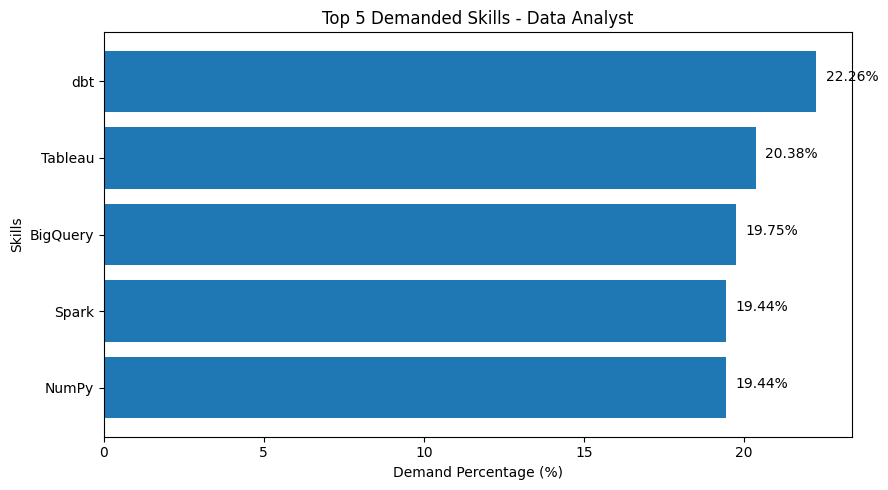

In [36]:
da_skills = ( job_skill_demand_analysis[ job_skill_demand_analysis['job_title'] == 'Data Analyst']
    .sort_values('demand_percentage', ascending=False)
    .head(5)
    .sort_values('demand_percentage'))

# Create horizontal bar chart
plt.figure(figsize=(9, 5))
plt.barh(
    da_skills['skill_name'],
    da_skills['demand_percentage'])
plt.xlabel('Demand Percentage (%)')
plt.ylabel('Skills')
plt.title('Top 5 Demanded Skills - Data Analyst')

for index, value in enumerate(da_skills['demand_percentage']):
    plt.text(value + 0.3, index, f'{value:.2f}%')
plt.tight_layout()
plt.show()

In [ ]:
# PIECHART

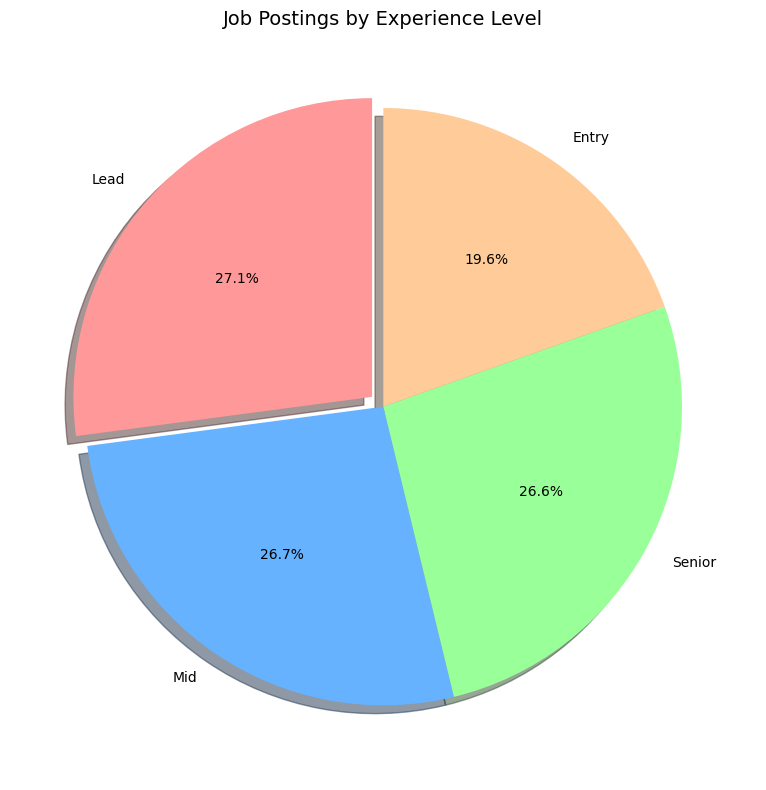

In [37]:
# Count jobs by experience level
experience_counts = postings['experience_level'].value_counts()
plt.figure(figsize=(8, 8))
plt.pie(
    experience_counts,
    labels=experience_counts.index,
    autopct='%1.1f%%',
    startangle=90,
    colors=['#FF9999', '#66B2FF', '#99FF99', '#FFCC99'],
    explode=[0.05, 0, 0, 0],
    shadow=True)

plt.title('Job Postings by Experience Level', fontsize=14)
plt.tight_layout()
plt.show()